# 02 - Analyse exploratoire des données (EDA)

**Objectif** : décrire les distributions des variables, les relations entre
le prix et ses variables explicatives (`annee`, `kilometrage`, `marque`,
`ville`) et les caractéristiques du marché, afin d'éclairer les choix de
modélisation (M4 régression, M5 clustering).

**Entrée** : `data/cleaned/used_car_ads_clean.csv` (sortie de `01_cleaning.ipynb`).

**Lecture seule** : ce notebook n'applique aucune transformation aux données
(ni suppression, ni imputation, ni encodage, ni scaling) et ne sauvegarde
rien : ni dataset, ni graphique. Les grandeurs dérivées (période, tranche de
kilométrage, logarithme du prix) sont calculées dans des variables locales,
uniquement pour l'affichage, et ne sont jamais ajoutées au DataFrame.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

COULEUR = "#2a78d6"
ENCRE = "#0b0b0b"
GRILLE = "#e5e5e2"

def format_dh(x, _):
    return f"{x:,.0f}".replace(",", " ")

def habiller(ax, axe_grille="y"):
    ax.grid(axis=axe_grille, color=GRILLE, linewidth=0.6)
    ax.set_axisbelow(True)
    for cote in ("top", "right"):
        ax.spines[cote].set_visible(False)

GRADUATIONS_PRIX = [20000, 50000, 100000, 200000, 500000, 1000000, 2000000]

def axe_prix_log(ax, axe="y"):
    # échelle logarithmique (affichage seulement) avec graduations lisibles en DH
    if axe == "y":
        ax.set_yscale("log")
        ax.set_yticks(GRADUATIONS_PRIX)
        ax.yaxis.set_major_formatter(FuncFormatter(format_dh))
        ax.yaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))
    else:
        ax.set_xscale("log")
        ax.set_xticks(GRADUATIONS_PRIX)
        ax.xaxis.set_major_formatter(FuncFormatter(format_dh))
        ax.xaxis.set_minor_formatter(FuncFormatter(lambda x, _: ""))

def fmt(x):
    return f"{x:,.0f}".replace(",", " ")

## 2. Présentation du dataset

In [2]:
CHEMIN = "../data/cleaned/used_car_ads_clean.csv"
df = pd.read_csv(CHEMIN)
print(f"Dimensions : {df.shape[0]} lignes × {df.shape[1]} colonnes")
print()
print("Colonnes et types :")
print(df.dtypes.to_string())
df.head()

Dimensions : 619 lignes × 8 colonnes

Colonnes et types :
marque            object
annee              int64
ville             object
kilometrage      float64
prix             float64
url_annonce       object
titre_annonce     object
date_collecte     object


,marque,annee,ville,kilometrage,prix,url_annonce,titre_annonce,date_collecte
0,Volkswagen,2020,Casablanca,NaN,350000.0,https://www.avito.ma/fr/anfa/voitures_d_occasi...,Volkswagen Golf 8 GTI 2020 dédouanée 2022,2026-11-17
1,Peugeot,2022,Tanger,140000.0,225000.0,https://www.avito.ma/fr/centre_ville/voitures_...,PEUGEOT 3008 Allure automatique,2026-11-17
2,BMW,2006,Tifelt,NaN,80000.0,https://www.avito.ma/fr/tifelt/voitures_d_occa...,"BMW 120d à vendre, prix raisonnable, offres bi...",2026-11-17
3,Opel,2021,Casablanca,38000.0,177000.0,https://www.avito.ma/fr/californie/voitures_d_...,Opel Astra diesel,2026-11-17
4,Peugeot,2017,Casablanca,180000.0,97000.0,https://www.avito.ma/fr/a%C3%AFn_chock/voiture...,Peugeot 208 modèle 2017,2026-11-17


In [3]:
print("Statistiques descriptives — variables numériques :")
df[["prix", "annee", "kilometrage"]].describe().round(0)

Statistiques descriptives — variables numériques :


,prix,annee,kilometrage
count,619.0,619.0,498.0
mean,266270.0,2019.0,119261.0
std,205934.0,6.0,68870.0
min,16000.0,1980.0,0.0
25%,145000.0,2017.0,70000.0
50%,210000.0,2021.0,113550.0
75%,316500.0,2023.0,155000.0
max,1850000.0,2026.0,413000.0


In [4]:
print("Statistiques descriptives — variables catégorielles :")
df[["marque", "ville"]].describe().rename(
    index={"count": "effectif", "unique": "modalités", "top": "plus fréquente", "freq": "fréquence"}
)

Statistiques descriptives — variables catégorielles :


,marque,ville
effectif,619,619
modalités,39,37
plus fréquente,Volkswagen,Casablanca
fréquence,70,227


In [5]:
print("Valeurs manquantes par colonne :")
pd.DataFrame({
    "manquantes": df.isna().sum(),
    "pourcentage": (df.isna().mean() * 100).round(1),
})

Valeurs manquantes par colonne :


,manquantes,pourcentage
marque,0,0.0
annee,0,0.0
ville,0,0.0
kilometrage,121,19.5
prix,0,0.0
url_annonce,0,0.0
titre_annonce,0,0.0
date_collecte,0,0.0


## 3. Valeurs manquantes du kilométrage

Les kilométrages manquants proviennent soit du parsing non récupérable,
soit des valeurs jugées invraisemblables en M2. On regarde si ces annonces
diffèrent des autres en année, en prix et en marque.

In [6]:
km_manquant = df["kilometrage"].isna()
print(f"Kilométrage manquant : {km_manquant.sum()} / {len(df)} ({km_manquant.mean() * 100:.1f} %)")
print(f"Kilométrage renseigné : {(~km_manquant).sum()} annonces")
print()

periode = pd.cut(df["annee"], bins=[0, 2010, 2015, 2020, 2026],
                 labels=["≤ 2010", "2011–2015", "2016–2020", "2021–2026"])
print("Part de kilométrages manquants par période :")
display(pd.DataFrame({
    "annonces": periode.value_counts(sort=False),
    "km manquant": km_manquant.groupby(periode, observed=False).sum(),
    "% manquant": (km_manquant.groupby(periode, observed=False).mean() * 100).round(1),
}))

Kilométrage manquant : 121 / 619 (19.5 %)
Kilométrage renseigné : 498 annonces

Part de kilométrages manquants par période :


,annonces,km manquant,% manquant
annee,,,
≤ 2010,47,12,25.5
2011–2015,77,18,23.4
2016–2020,177,40,22.6
2021–2026,318,51,16.0


Prix selon la présence du kilométrage :


,count,mean,std,min,25%,50%,75%,max
kilometrage,,,,,,,,
avec kilométrage,498.0,270335.0,211363.0,16000.0,145000.0,215000.0,320000.0,1850000.0
sans kilométrage,121.0,249537.0,181739.0,35000.0,135000.0,192000.0,287000.0,1240000.0


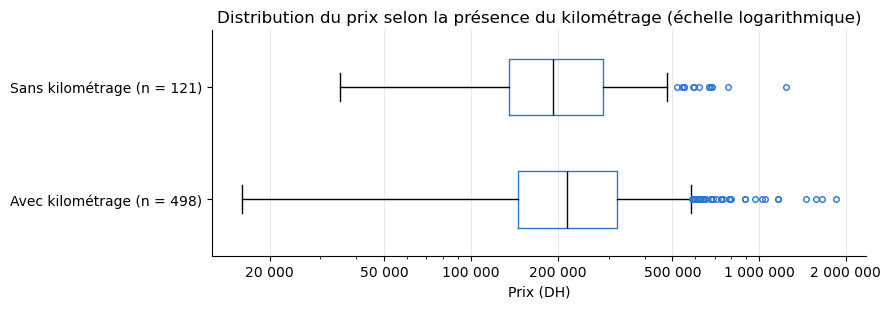

In [7]:
print("Prix selon la présence du kilométrage :")
comparaison_prix = df.groupby(km_manquant.map({False: "avec kilométrage", True: "sans kilométrage"}))["prix"].describe()
display(comparaison_prix.round(0))

fig, ax = plt.subplots(figsize=(9, 3.2))
ax.boxplot([df.loc[~km_manquant, "prix"], df.loc[km_manquant, "prix"]], vert=False, widths=0.5,
           tick_labels=[f"Avec kilométrage (n = {(~km_manquant).sum()})", f"Sans kilométrage (n = {km_manquant.sum()})"],
           boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=4, markeredgecolor=COULEUR))
axe_prix_log(ax, "x")
ax.set_title("Distribution du prix selon la présence du kilométrage (échelle logarithmique)")
ax.set_xlabel("Prix (DH)")
habiller(ax, "x")
fig.tight_layout()
plt.show()

In [8]:
print("Marques les plus concernées par les kilométrages manquants (effectif ≥ 10) :")
par_marque = df.groupby("marque").agg(annonces=("prix", "size"), km_manquant=("kilometrage", lambda s: s.isna().sum()))
par_marque["% manquant"] = (par_marque["km_manquant"] / par_marque["annonces"] * 100).round(1)
par_marque[par_marque["annonces"] >= 10].sort_values("km_manquant", ascending=False).head(10)

Marques les plus concernées par les kilométrages manquants (effectif ≥ 10) :


,annonces,km_manquant,% manquant
marque,,,
Mercedes-Benz,61,19,31.1
Peugeot,45,15,33.3
Volkswagen,70,13,18.6
Audi,38,8,21.1
Renault,43,8,18.6
BMW,42,6,14.3
Porsche,19,5,26.3
Citroën,19,5,26.3
Dacia,30,5,16.7


**Interprétation**

- 121 annonces sur 619 (19,5 %) n'ont pas de kilométrage.
- La part de valeurs manquantes **varie selon l'ancienneté** : 25,5 % pour
  les véhicules de 2010 ou avant, contre 16,0 % pour ceux de 2021–2026.
- Les annonces sans kilométrage ont un prix médian un peu plus bas :
  192 000 DH, contre 215 000 DH avec kilométrage. Les deux distributions se
  recouvrent toutefois largement.
- Certaines marques sont plus touchées que d'autres : Peugeot (33,3 %),
  Mercedes-Benz (31,1 %).

Les valeurs manquantes ne se répartissent donc pas de façon uniforme : elles
sont **associées** à l'année, au prix et à la marque.

**Limite de cette analyse** : ces constats décrivent des associations, ils
ne permettent **pas** d'identifier le mécanisme réel des valeurs manquantes
(complètement aléatoire, aléatoire conditionnellement aux variables
observées, ou lié à la valeur manquante elle-même). Une analyse descriptive
sur 619 annonces ne peut pas trancher ce point. Les écarts observés sont de
plus modestes et portent sur des sous-groupes parfois petits.

**Conséquences** :
- Travailler uniquement sur les annonces complètes (n = 498) pourrait
  légèrement sur-représenter les véhicules récents.
- M4 devra choisir explicitement entre deux options : imputation (par
  exemple selon l'année), éventuellement accompagnée d'un indicateur de
  valeur manquante, ou modèle qui tolère les NaN.
- M5 devra faire le même choix avant le scaling.

## 4. Analyse univariée

### 4.1 Prix

In [9]:
prix = df["prix"]
log_prix = np.log(prix)  # variable locale, uniquement pour comparer les distributions

stats_prix = pd.Series({
    "moyenne": prix.mean(), "médiane": prix.median(), "écart-type": prix.std(),
    "minimum": prix.min(), "Q1": prix.quantile(0.25), "Q3": prix.quantile(0.75), "maximum": prix.max(),
})
print("Statistiques du prix (DH) :")
print(stats_prix.map(fmt).to_string())
print()
forme = pd.DataFrame({
    "asymétrie": [stats.skew(prix), stats.skew(log_prix)],
    "kurtosis (excès)": [stats.kurtosis(prix), stats.kurtosis(log_prix)],
}, index=["prix", "log(prix)"]).round(2)
print("Forme de la distribution :")
forme

Statistiques du prix (DH) :
moyenne         266 270
médiane         210 000
écart-type      205 934
minimum          16 000
Q1              145 000
Q3              316 500
maximum       1 850 000

Forme de la distribution :


,asymétrie,kurtosis (excès)
prix,3.09,14.57
log(prix),0.12,0.85


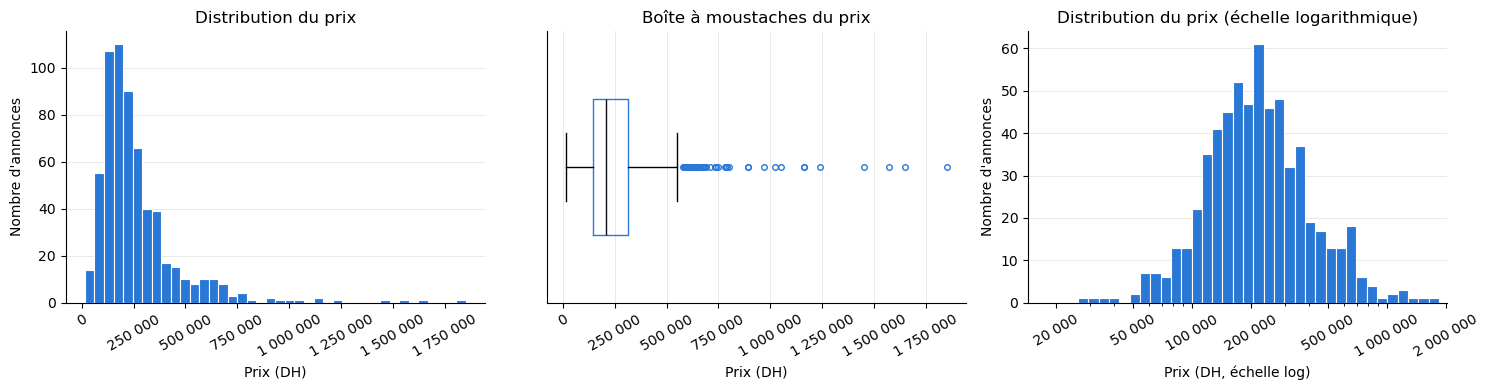

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.hist(prix, bins=40, color=COULEUR, edgecolor="white", linewidth=0.8)
ax.set_title("Distribution du prix")
ax.set_xlabel("Prix (DH)")
ax.set_ylabel("Nombre d'annonces")
ax.xaxis.set_major_formatter(FuncFormatter(format_dh))
habiller(ax)

ax = axes[1]
ax.boxplot(prix, vert=False, widths=0.5, boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=4, markeredgecolor=COULEUR))
ax.set_title("Boîte à moustaches du prix")
ax.set_xlabel("Prix (DH)")
ax.set_yticks([])
ax.xaxis.set_major_formatter(FuncFormatter(format_dh))
habiller(ax, "x")

ax = axes[2]
ax.hist(prix, bins=np.logspace(np.log10(prix.min()), np.log10(prix.max()), 40),
        color=COULEUR, edgecolor="white", linewidth=0.8)
axe_prix_log(ax, "x")
ax.set_xlim(prix.min() * 0.9, prix.max() * 1.1)
ax.set_title("Distribution du prix (échelle logarithmique)")
ax.set_xlabel("Prix (DH, échelle log)")
ax.set_ylabel("Nombre d'annonces")
habiller(ax)
for a in axes:
    a.tick_params(axis="x", labelrotation=30)
fig.tight_layout()
plt.show()

**Interprétation**

- La distribution du prix est **fortement asymétrique à droite** :
  - la moyenne (266 270 DH) dépasse nettement la médiane (210 000 DH) ;
  - l'asymétrie vaut 3,09 et l'excès de kurtosis 14,57.
- La moitié centrale des annonces se situe entre 145 000 et 316 500 DH.
- La longue queue droite correspond aux véhicules haut de gamme conservés
  en M2, jusqu'à 1 850 000 DH.
- Sur l'échelle logarithmique, la distribution devient presque symétrique
  (asymétrie 0,12, kurtosis 0,85).

Ce constat est important pour le choix de la cible en M4. Le log ne sert ici
qu'à comparer les distributions : il n'est pas ajouté aux données.

### 4.2 Kilométrage

Annonces avec kilométrage : n = 498 — manquantes : 121

Statistiques du kilométrage (km) :
effectif          498
moyenne       119 261
écart-type     68 870
minimum             0
Q1             70 000
médiane       113 550
Q3            155 000
maximum       413 000
asymétrie      0.74
kurtosis       0.92


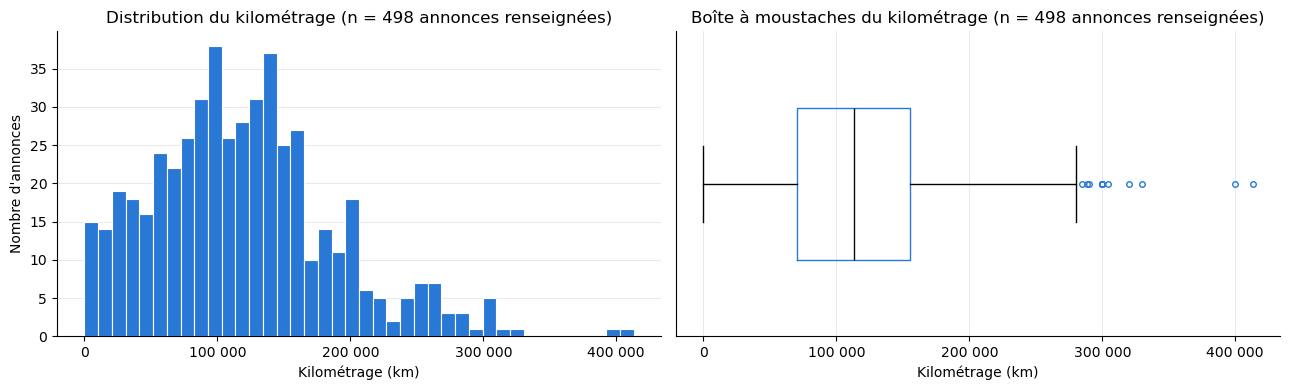

In [11]:
km = df["kilometrage"].dropna()  # sous-ensemble local, df n'est pas modifié
print(f"Annonces avec kilométrage : n = {len(km)} — manquantes : {df['kilometrage'].isna().sum()}")
print()
print("Statistiques du kilométrage (km) :")
print(km.describe().rename({"count": "effectif", "mean": "moyenne", "std": "écart-type", "min": "minimum",
                            "25%": "Q1", "50%": "médiane", "75%": "Q3", "max": "maximum"}).map(fmt).to_string())
print(f"asymétrie      {stats.skew(km):.2f}")
print(f"kurtosis       {stats.kurtosis(km):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
ax = axes[0]
ax.hist(km, bins=40, color=COULEUR, edgecolor="white", linewidth=0.8)
ax.set_title(f"Distribution du kilométrage (n = {len(km)} annonces renseignées)")
ax.set_xlabel("Kilométrage (km)")
ax.set_ylabel("Nombre d'annonces")
habiller(ax)
ax = axes[1]
ax.boxplot(km, vert=False, widths=0.5, boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=4, markeredgecolor=COULEUR))
ax.set_title(f"Boîte à moustaches du kilométrage (n = {len(km)} annonces renseignées)")
ax.set_xlabel("Kilométrage (km)")
ax.set_yticks([])
habiller(ax, "x")
for a in axes:
    a.xaxis.set_major_formatter(FuncFormatter(format_dh))
fig.tight_layout()
plt.show()

**Interprétation** (n = 498 annonces renseignées, 121 manquantes)

- Le kilométrage est modérément asymétrique à droite (asymétrie 0,74,
  kurtosis 0,92).
- Médiane : 113 550 km. Moitié centrale : entre 70 000 et 155 000 km.
- Le pic proche de 0 km correspond aux véhicules neufs ou très récents
  (millésime 2026), conservés en M2.
- Les valeurs d'au moins 300 000 km sont rares (5 annonces, maximum
  413 000 km).

Les statistiques ne portent que sur les annonces renseignées : elles ne
représentent pas nécessairement les 121 annonces sans kilométrage (voir la
section 3).

### 4.3 Année

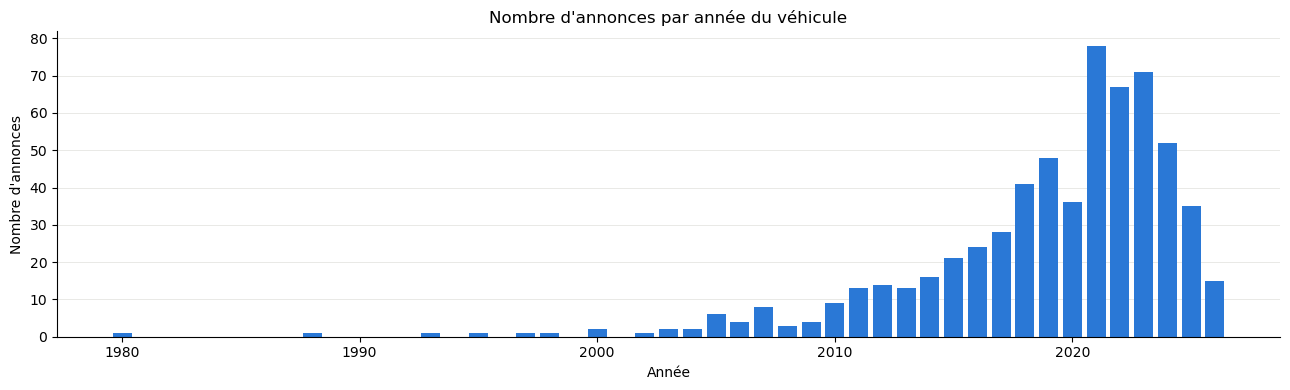

Année la plus représentée : 2021 (78 annonces)

Répartition par période :


,annonces,%
annee,,
≤ 2010,47,7.6
2011–2015,77,12.4
2016–2020,177,28.6
2021–2026,318,51.4


In [12]:
par_annee = df["annee"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(par_annee.index, par_annee.values, color=COULEUR, width=0.8)
ax.set_title("Nombre d'annonces par année du véhicule")
ax.set_xlabel("Année")
ax.set_ylabel("Nombre d'annonces")
habiller(ax)
fig.tight_layout()
plt.show()

print(f"Année la plus représentée : {par_annee.idxmax()} ({par_annee.max()} annonces)")
print()
print("Répartition par période :")
pd.DataFrame({"annonces": periode.value_counts(sort=False),
              "%": (periode.value_counts(sort=False, normalize=True) * 100).round(1)})

**Interprétation**

- Le marché observé est **récent** : 51,4 % des annonces concernent des
  véhicules de 2021–2026 et 28,6 % des véhicules de 2016–2020.
- L'année la plus représentée est 2021 (78 annonces).
- Les véhicules de 2010 ou avant ne représentent que 7,6 % des annonces
  (47). Avant 2005, on compte au plus 2 annonces par année.
- Les conclusions sur les véhicules anciens reposent donc sur peu
  d'observations.

### 4.4 Marque

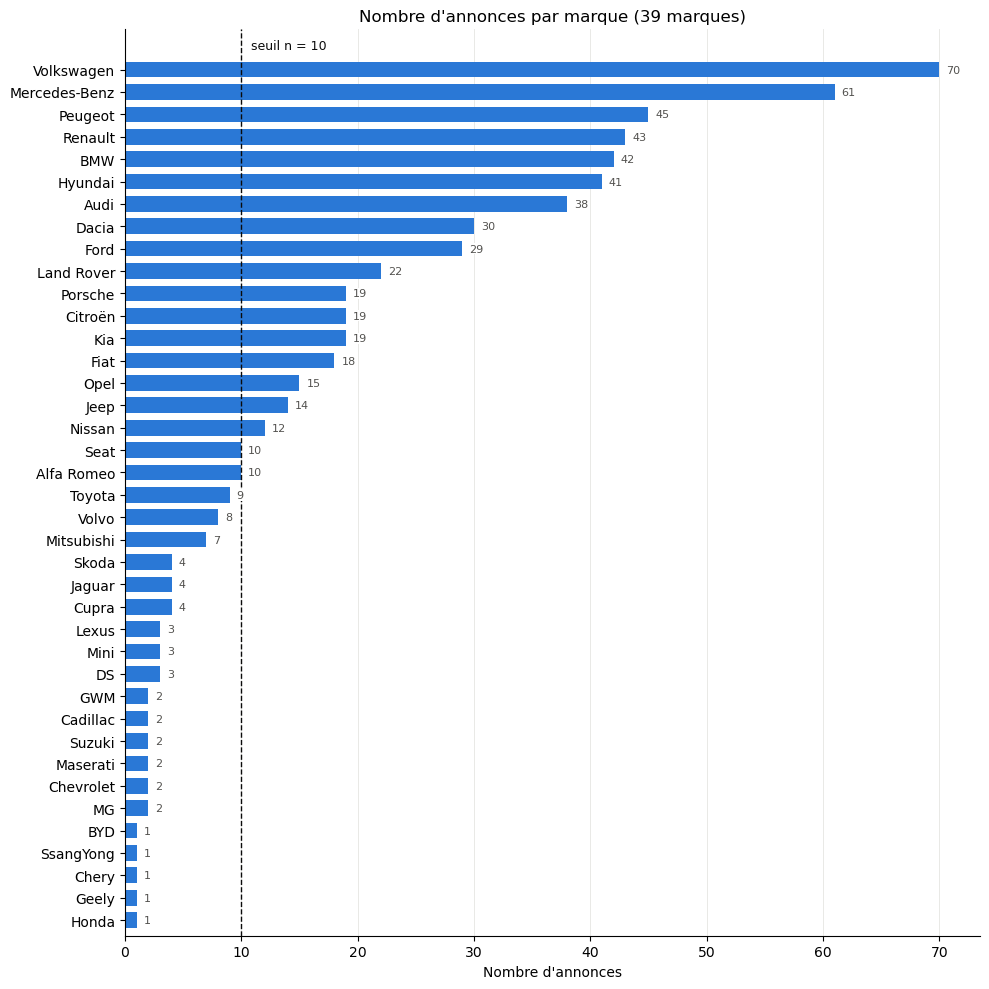

Marques avec au moins 10 annonces : 19 (557 annonces, 90.0 %)
Marques rares (< 10 annonces) : 20 — dont 11 avec 1 ou 2 annonces
Toyota (9), Volvo (8), Mitsubishi (7), Jaguar (4), Skoda (4), Cupra (4), DS (3), Lexus (3), Mini (3), GWM (2), Chevrolet (2), Maserati (2), MG (2), Cadillac (2), Suzuki (2), Chery (1), BYD (1), Honda (1), Geely (1), SsangYong (1)


In [13]:
SEUIL_MARQUE = 10
par_marque_n = df["marque"].value_counts()

fig, ax = plt.subplots(figsize=(10, 10))
ordre = par_marque_n.sort_values()
ax.barh(ordre.index, ordre.values, color=COULEUR, height=0.7)
ax.axvline(SEUIL_MARQUE, color=ENCRE, linewidth=1, linestyle="--")
ax.text(SEUIL_MARQUE + 0.8, len(ordre) - 0.2, f"seuil n = {SEUIL_MARQUE}", color=ENCRE, fontsize=9, va="bottom")
for i, v in enumerate(ordre.values):
    ax.text(v + 0.6, i, str(v), va="center", fontsize=8, color="#52514e",
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))
ax.set_ylim(-0.7, len(ordre) + 0.8)
ax.set_title(f"Nombre d'annonces par marque ({par_marque_n.size} marques)")
ax.set_xlabel("Nombre d'annonces")
habiller(ax, "x")
fig.tight_layout()
plt.show()

rares = par_marque_n[par_marque_n < SEUIL_MARQUE]
print(f"Marques avec au moins {SEUIL_MARQUE} annonces : {(par_marque_n >= SEUIL_MARQUE).sum()} "
      f"({par_marque_n[par_marque_n >= SEUIL_MARQUE].sum()} annonces, "
      f"{par_marque_n[par_marque_n >= SEUIL_MARQUE].sum() / len(df) * 100:.1f} %)")
print(f"Marques rares (< {SEUIL_MARQUE} annonces) : {rares.size} — dont {(par_marque_n <= 2).sum()} avec 1 ou 2 annonces")
print(", ".join(f"{m} ({n})" for m, n in rares.items()))

**Interprétation**

- 19 marques ont au moins 10 annonces et couvrent 90,0 % du dataset.
- Volkswagen (70) et Mercedes-Benz (61) dominent, suivies de Peugeot,
  Renault, BMW et Hyundai.
- 20 marques sont rares (moins de 10 annonces), dont 11 avec seulement 1 ou
  2 annonces.
  - L'inspection préliminaire comptait 9 marques à 1 ou 2 annonces. Le
    recalcul dans ce notebook en donne **11** : c'est ce chiffre qui fait
    foi.
- Ces modalités rares ne permettent pas d'estimer un effet de marque
  fiable.

### 4.5 Ville

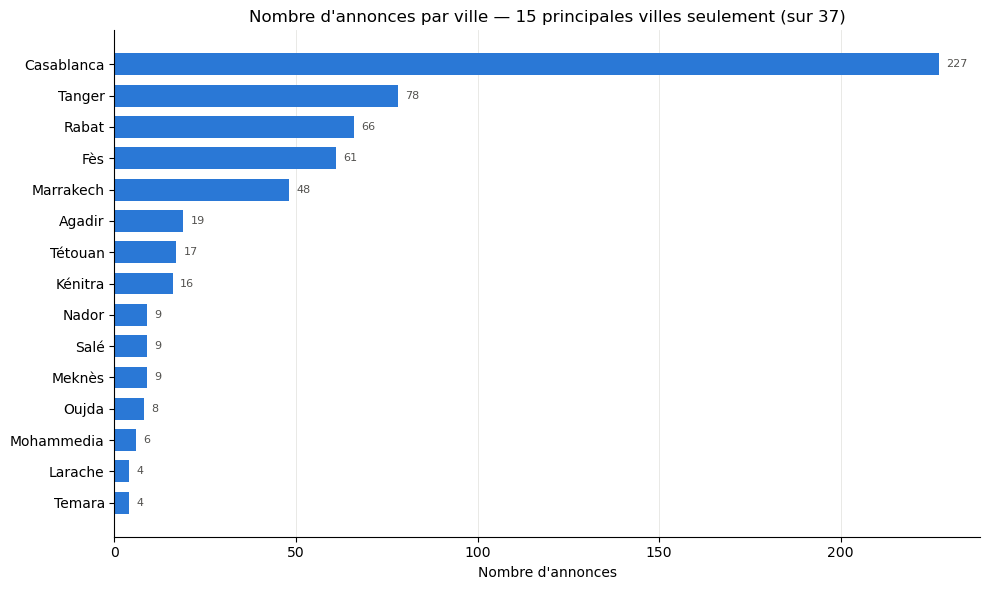

Villes distinctes : 37
Casablanca : 227 annonces (36.7 %)
5 premières villes : 480 annonces (77.5 %)
Villes avec au moins 15 annonces : 8
Villes avec 2 annonces ou moins : 19


In [14]:
par_ville = df["ville"].value_counts()
top15 = par_ville.head(15).sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top15.index, top15.values, color=COULEUR, height=0.7)
for i, v in enumerate(top15.values):
    ax.text(v + 2, i, str(v), va="center", fontsize=8, color="#52514e")
ax.set_title(f"Nombre d'annonces par ville — 15 principales villes seulement (sur {par_ville.size})")
ax.set_xlabel("Nombre d'annonces")
habiller(ax, "x")
fig.tight_layout()
plt.show()

print(f"Villes distinctes : {par_ville.size}")
print(f"Casablanca : {par_ville['Casablanca']} annonces ({par_ville['Casablanca'] / len(df) * 100:.1f} %)")
print(f"5 premières villes : {par_ville.head(5).sum()} annonces ({par_ville.head(5).sum() / len(df) * 100:.1f} %)")
print(f"Villes avec au moins 15 annonces : {(par_ville >= 15).sum()}")
print(f"Villes avec 2 annonces ou moins : {(par_ville <= 2).sum()}")

**Interprétation**

- Les annonces sont très concentrées géographiquement :
  - Casablanca à elle seule regroupe 36,7 % des annonces (227) ;
  - les 5 premières villes (Casablanca, Tanger, Rabat, Fès, Marrakech) en
    regroupent 77,5 %.
- Seules 8 villes ont au moins 15 annonces.
- 19 villes ont 2 annonces ou moins.
  - L'inspection préliminaire en comptait 20. Le recalcul donne **19** :
    c'est ce chiffre qui fait foi.

## 5. Analyse bivariée : prix selon les variables explicatives

### 5.A Prix et année

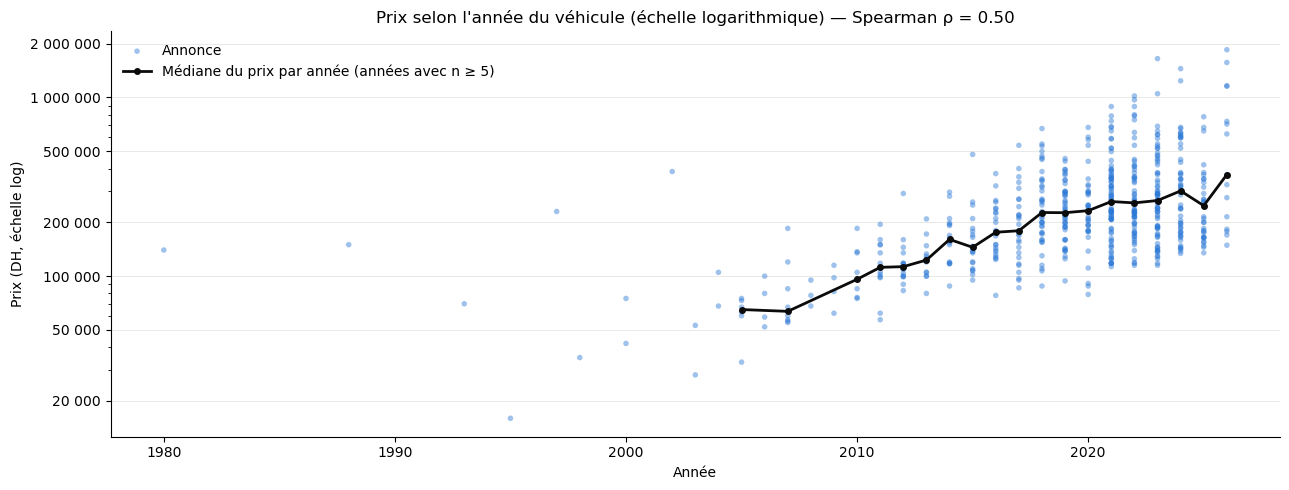

Corrélation de Spearman prix–année : ρ = 0.50 (p = 1.7e-40)


In [15]:
SEUIL_ANNEE = 5
effectif_annee = df["annee"].value_counts()
annees_suffisantes = effectif_annee[effectif_annee >= SEUIL_ANNEE].index
mediane_annee = df[df["annee"].isin(annees_suffisantes)].groupby("annee")["prix"].median()
rho_annee, p_annee = stats.spearmanr(df["annee"], df["prix"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(df["annee"], df["prix"], s=16, color=COULEUR, alpha=0.45, edgecolors="none", label="Annonce")
ax.plot(mediane_annee.index, mediane_annee.values, color=ENCRE, linewidth=2, marker="o", markersize=4,
        label=f"Médiane du prix par année (années avec n ≥ {SEUIL_ANNEE})")
axe_prix_log(ax, "y")
ax.set_title(f"Prix selon l'année du véhicule (échelle logarithmique) — Spearman ρ = {rho_annee:.2f}")
ax.set_xlabel("Année")
ax.set_ylabel("Prix (DH, échelle log)")
ax.legend(frameon=False)
habiller(ax)
fig.tight_layout()
plt.show()

print(f"Corrélation de Spearman prix–année : ρ = {rho_annee:.2f} (p = {p_annee:.1e})")

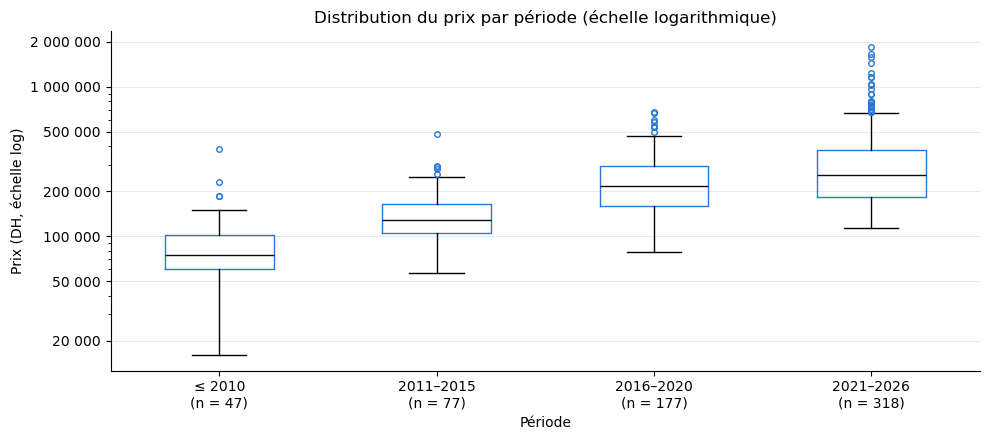

Prix médian par période (DH) :
annee
≤ 2010        75 000
2011–2015    129 000
2016–2020    215 000
2021–2026    258 500


In [16]:
groupes = [df.loc[periode == p, "prix"] for p in periode.cat.categories]
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.boxplot(groupes, widths=0.5,
           tick_labels=[f"{p}\n(n = {len(g)})" for p, g in zip(periode.cat.categories, groupes)],
           boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=4, markeredgecolor=COULEUR))
axe_prix_log(ax, "y")
ax.set_title("Distribution du prix par période (échelle logarithmique)")
ax.set_xlabel("Période")
ax.set_ylabel("Prix (DH, échelle log)")
habiller(ax)
fig.tight_layout()
plt.show()

print("Prix médian par période (DH) :")
print(df.groupby(periode, observed=False)["prix"].median().map(fmt).to_string())

**Interprétation**

- La relation entre année et prix est **positive et nette** (Spearman
  ρ = 0,50) : plus le véhicule est récent, plus il est cher.
- Le prix médian passe de 75 000 DH (2010 ou avant) à 129 000 DH
  (2011–2015), puis 215 000 DH (2016–2020) et 258 500 DH (2021–2026).
- Pour une même année récente, la dispersion reste très forte : de moins de
  100 000 DH à plus de 1 000 000 DH. L'année ne suffit donc pas à expliquer
  le prix, et la marque joue un rôle important.
- La médiane n'est tracée que pour les années ayant au moins 5 annonces :
  avant 2005, les effectifs (1 ou 2 annonces) rendent la courbe
  instable.

### 5.B Prix et kilométrage

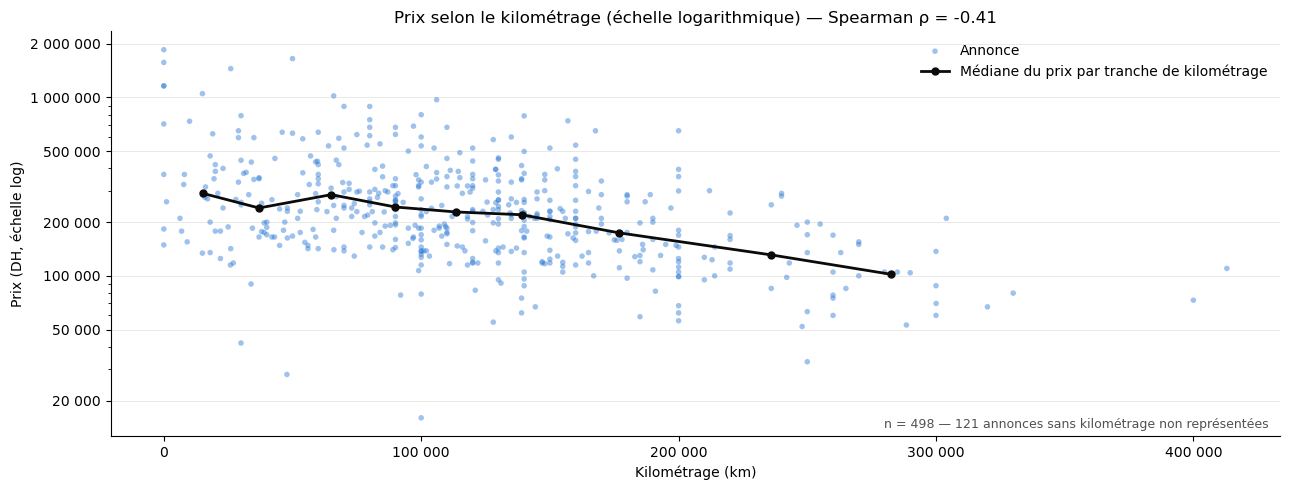

Corrélation de Spearman prix–kilométrage : ρ = -0.41 (p = 2.9e-21), n = 498
Note : 121 annonces sans kilométrage non représentées.

Prix médian par tranche de kilométrage :


,annonces,prix médian (DH)
kilometrage,,
"(-1, 25000]",35,290 000
"(25000, 50000]",47,240 000
"(50000, 75000]",53,285 000
"(75000, 100000]",83,243 000
"(100000, 125000]",62,228 000
"(125000, 150000]",87,220 000
"(150000, 200000]",83,174 000
"(200000, 250000]",24,131 000
"(250000, 500000]",24,102 000


In [17]:
avec_km = df["kilometrage"].notna()
x_km, y_prix = df.loc[avec_km, "kilometrage"], df.loc[avec_km, "prix"]
tranche_km = pd.cut(x_km, bins=[-1, 25000, 50000, 75000, 100000, 125000, 150000, 200000, 250000, 500000])
centre_tranche = x_km.groupby(tranche_km, observed=True).median()
mediane_tranche = y_prix.groupby(tranche_km, observed=True).median()
rho_km, p_km = stats.spearmanr(x_km, y_prix)

fig, ax = plt.subplots(figsize=(13, 5))
ax.scatter(x_km, y_prix, s=16, color=COULEUR, alpha=0.45, edgecolors="none", label="Annonce")
ax.plot(centre_tranche.values, mediane_tranche.values, color=ENCRE, linewidth=2, marker="o", markersize=5,
        label="Médiane du prix par tranche de kilométrage")
axe_prix_log(ax, "y")
ax.xaxis.set_major_formatter(FuncFormatter(format_dh))
ax.set_title(f"Prix selon le kilométrage (échelle logarithmique) — Spearman ρ = {rho_km:.2f}")
ax.set_xlabel("Kilométrage (km)")
ax.set_ylabel("Prix (DH, échelle log)")
ax.legend(frameon=False)
ax.text(0.99, 0.02, f"n = {avec_km.sum()} — {(~avec_km).sum()} annonces sans kilométrage non représentées",
        transform=ax.transAxes, ha="right", fontsize=9, color="#52514e")
habiller(ax)
fig.tight_layout()
plt.show()

print(f"Corrélation de Spearman prix–kilométrage : ρ = {rho_km:.2f} (p = {p_km:.1e}), n = {avec_km.sum()}")
print("Note : 121 annonces sans kilométrage non représentées.")
print()
print("Prix médian par tranche de kilométrage :")
display(pd.DataFrame({"annonces": tranche_km.value_counts(sort=False),
                      "prix médian (DH)": mediane_tranche.map(fmt)}))

In [18]:
cols = ["marque", "annee", "kilometrage", "prix", "titre_annonce"]
print("Annonces visuellement atypiques — prix élevé (≥ 500 000 DH) malgré un kilométrage ≥ 100 000 km :")
print(df[(df["kilometrage"] >= 100000) & (df["prix"] >= 500000)][cols].to_string())
print()
print("Annonces visuellement atypiques — kilométrage ≥ 300 000 km :")
print(df[df["kilometrage"] >= 300000][cols].to_string())

Annonces visuellement atypiques — prix élevé (≥ 500 000 DH) malgré un kilométrage ≥ 100 000 km :
            marque  annee  kilometrage      prix                                       titre_annonce
84         Porsche   2020     128000.0  580000.0                        Porsche Cayenne Hybride 2020
151            BMW   2020     135000.0  600000.0                        BMW X6 M full, très bon état
190           Audi   2023     100000.0  535000.0  Audi Q3 Diesel 2023 dédouanée 2025 Sportback Sline
228  Mercedes-Benz   2021     140000.0  788000.0              MERCEDES-BENZ GLE 350 DE COUPÉ hybride
245     Land Rover   2021     105000.0  520000.0                              Range Rover Sport 2021
295  Mercedes-Benz   2022     106000.0  970000.0                    Classe S400 4MATIC AMG Line Plus
316        Porsche   2020     110000.0  680000.0                               PORSCHE CAYENNE COUPÉ
325  Mercedes-Benz   2017     160000.0  540000.0      Mercedes-Benz Classe S Diesel Automatique

**Interprétation** (121 annonces sans kilométrage non représentées)

- La relation entre kilométrage et prix est **négative et modérée**
  (Spearman ρ = −0,41).
- Le prix médian baisse de 290 000 DH (moins de 25 000 km) à 102 000 DH
  (plus de 250 000 km).
- La relation n'est pas linéaire : on observe un plateau entre 0 et environ
  150 000 km (médianes de 220 000 à 290 000 DH), puis une baisse plus
  nette.
- Observations visuellement atypiques :
  - 15 véhicules premium (Porsche Cayenne et Macan, Mercedes GLE et
    Classe S, BMW X5, X6 et X7…) restent au-dessus de 500 000 DH malgré au
    moins 100 000 km ;
  - 5 véhicules anciens atteignent ou dépassent 300 000 km.

  Ces observations sont plausibles. La marque peut compenser l'effet du
  kilométrage, ce qui suggère des interactions.

### 5.C Prix et marque

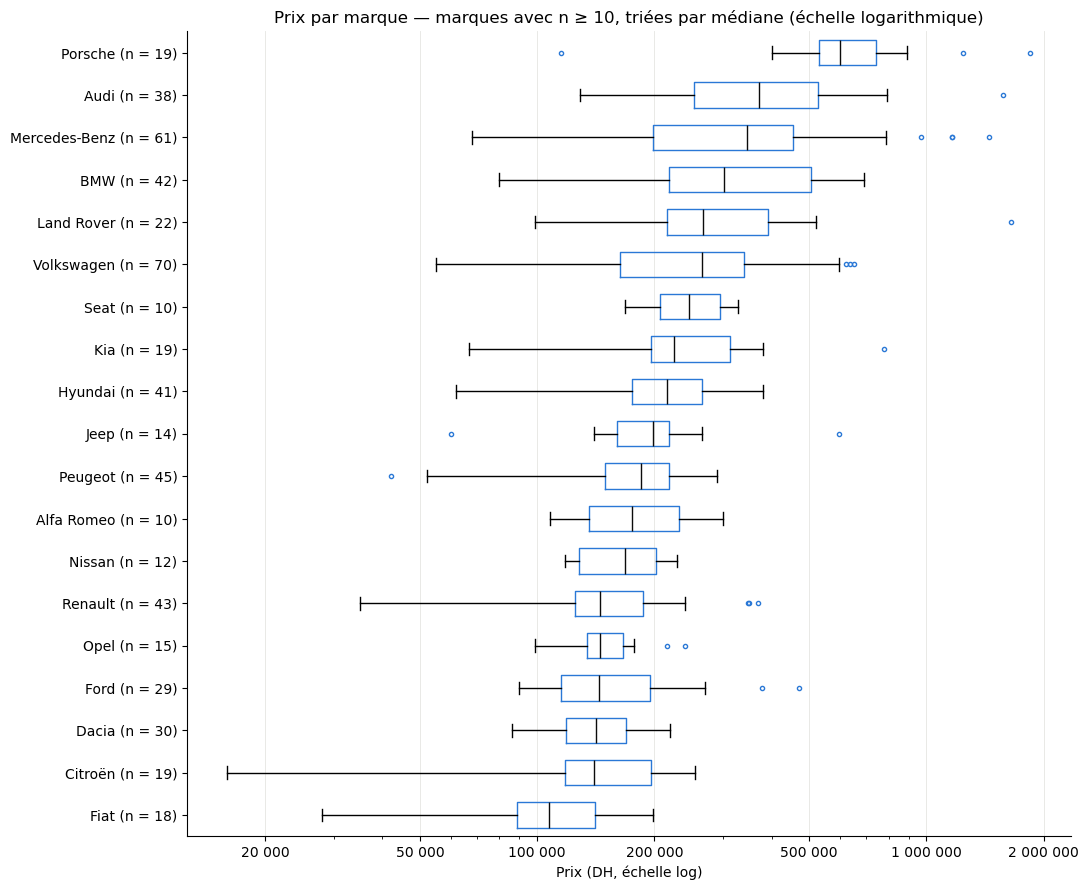

In [19]:
grandes_marques = par_marque_n[par_marque_n >= SEUIL_MARQUE].index
ordre_marques = df[df["marque"].isin(grandes_marques)].groupby("marque")["prix"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 9))
ax.boxplot([df.loc[df["marque"] == m, "prix"] for m in ordre_marques], vert=False, widths=0.6,
           tick_labels=[f"{m} (n = {par_marque_n[m]})" for m in ordre_marques],
           boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=3, markeredgecolor=COULEUR))
axe_prix_log(ax, "x")
ax.set_title(f"Prix par marque — marques avec n ≥ {SEUIL_MARQUE}, triées par médiane (échelle logarithmique)")
ax.set_xlabel("Prix (DH, échelle log)")
habiller(ax, "x")
fig.tight_layout()
plt.show()

In [20]:
resume_marques = df.groupby("marque")["prix"].agg(
    n="size", mediane="median", Q1=lambda s: s.quantile(0.25), Q3=lambda s: s.quantile(0.75)
).sort_values("mediane", ascending=False)
tableau_marques = pd.DataFrame({
    "n": resume_marques["n"],
    "médiane (DH)": resume_marques["mediane"].map(fmt),
    "Q1–Q3 (DH)": resume_marques["Q1"].map(fmt) + " – " + resume_marques["Q3"].map(fmt),
    "effectif faible (n < 10)": np.where(resume_marques["n"] < SEUIL_MARQUE, "oui", ""),
})
print(f"Récapitulatif du prix pour les {len(tableau_marques)} marques (triées par médiane) :")
pd.set_option("display.max_rows", 60)
tableau_marques

Récapitulatif du prix pour les 39 marques (triées par médiane) :


,n,médiane (DH),Q1–Q3 (DH),effectif faible (n < 10)
marque,,,,
Cadillac,2,1 035 000,1 027 500 – 1 042 500,oui
Porsche,19,600 000,530 000 – 740 000,
Audi,38,371 500,253 000 – 525 750,
BYD,1,370 000,370 000 – 370 000,oui
Mercedes-Benz,61,345 000,198 000 – 455 000,
Cupra,4,327 500,320 000 – 356 250,oui
BMW,42,302 500,218 000 – 503 750,
DS,3,295 000,263 500 – 310 000,oui
Lexus,3,275 000,272 500 – 285 000,oui


**Interprétation**

- Les prix diffèrent **fortement** selon la marque. Parmi les marques ayant
  au moins 10 annonces, la médiane va de 107 500 DH (Fiat) à 600 000 DH
  (Porsche), soit un rapport de 5,6.
- On distingue trois groupes :
  - un groupe haut de gamme : Porsche, Audi, Mercedes-Benz, BMW, Land
    Rover ;
  - un groupe intermédiaire : Volkswagen, Seat, Kia, Hyundai ;
  - un groupe généraliste plus abordable : Renault, Dacia, Ford, Citroën,
    Fiat, Opel.
- Les intervalles interquartiles se chevauchent beaucoup entre marques
  voisines.

**Mise en garde** : pour les 20 marques avec moins de 10 annonces, la
médiane et les quartiles sont très instables. Par exemple, Cadillac affiche
une médiane de 1 035 000 DH sur 2 annonces seulement, et BYD ou Geely
reposent sur une seule annonce. On ne peut tirer aucune conclusion de ces
valeurs.

### 5.D Prix et ville

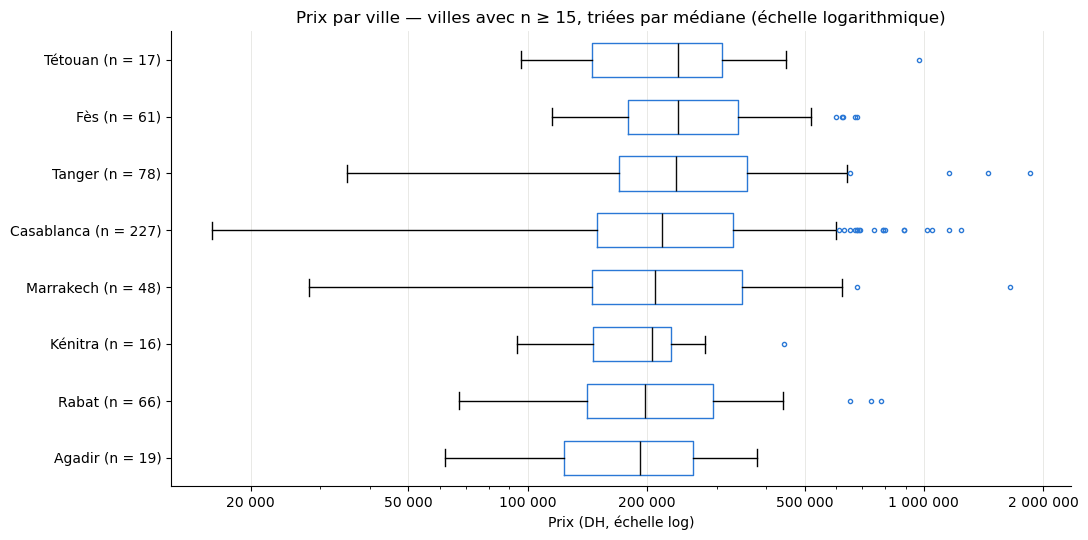

In [21]:
SEUIL_VILLE = 15
grandes_villes = par_ville[par_ville >= SEUIL_VILLE].index
ordre_villes = df[df["ville"].isin(grandes_villes)].groupby("ville")["prix"].median().sort_values().index

fig, ax = plt.subplots(figsize=(11, 5.5))
ax.boxplot([df.loc[df["ville"] == v, "prix"] for v in ordre_villes], vert=False, widths=0.6,
           tick_labels=[f"{v} (n = {par_ville[v]})" for v in ordre_villes],
           boxprops=dict(color=COULEUR), medianprops=dict(color=ENCRE),
           flierprops=dict(marker="o", markersize=3, markeredgecolor=COULEUR))
axe_prix_log(ax, "x")
ax.set_title(f"Prix par ville — villes avec n ≥ {SEUIL_VILLE}, triées par médiane (échelle logarithmique)")
ax.set_xlabel("Prix (DH, échelle log)")
habiller(ax, "x")
fig.tight_layout()
plt.show()

**Hypothèse d'analyse — marques « premium »** : pour examiner la
composition des villes, on regroupe sous l'étiquette « premium » les marques
suivantes : Porsche, Land Rover, Mercedes-Benz, BMW, Audi, Jaguar, Maserati,
Lexus, Cadillac. Cette liste est un **choix manuel**, fondé sur le
positionnement commercial usuel de ces marques. Ce n'est pas une
classification objective : d'autres définitions (incluant Volvo, Mini ou DS
par exemple) changeraient légèrement les pourcentages ci-dessous. Elle sert
uniquement à cette lecture descriptive.

In [22]:
MARQUES_PREMIUM = ["Porsche", "Land Rover", "Mercedes-Benz", "BMW", "Audi",
                   "Jaguar", "Maserati", "Lexus", "Cadillac"]
est_premium = df["marque"].isin(MARQUES_PREMIUM)  # Series locale, df n'est pas modifié

sous_ensemble = df["ville"].isin(grandes_villes)
composition = pd.DataFrame({
    "n": df[sous_ensemble].groupby("ville").size(),
    "prix médian (DH)": df[sous_ensemble].groupby("ville")["prix"].median(),
    "% premium": (est_premium[sous_ensemble].groupby(df.loc[sous_ensemble, "ville"]).mean() * 100).round(1),
    "année médiane": df[sous_ensemble].groupby("ville")["annee"].median(),
}).sort_values("prix médian (DH)", ascending=False)
composition["prix médian (DH)"] = composition["prix médian (DH)"].map(fmt)
print(f"Part des marques premium (hypothèse d'analyse) dans l'ensemble du dataset : {est_premium.mean() * 100:.1f} %")
print()
print(f"Composition des villes avec n ≥ {SEUIL_VILLE} :")
composition

Part des marques premium (hypothèse d'analyse) dans l'ensemble du dataset : 31.2 %

Composition des villes avec n ≥ 15 :


,n,prix médian (DH),% premium,année médiane
ville,,,,
Fès,61,240 000,19.7,2023.0
Tétouan,17,240 000,23.5,2022.0
Tanger,78,236 500,35.9,2020.5
Casablanca,227,218 000,40.5,2021.0
Marrakech,48,210 000,29.2,2021.5
Kénitra,16,206 000,25.0,2021.0
Rabat,66,198 000,33.3,2019.0
Agadir,19,192 000,5.3,2020.0


**Interprétation**

- Les écarts entre villes sont **bien plus faibles** qu'entre marques. Pour
  les villes ayant au moins 15 annonces, la médiane va de 192 000 DH
  (Agadir) à 240 000 DH (Fès, Tétouan).
- Les boîtes se recouvrent presque entièrement.
- La composition des annonces diffère d'une ville à l'autre :
  - Casablanca compte 40,5 % de marques premium (hypothèse d'analyse
    ci-dessus), contre 5,3 % à Agadir ;
  - Fès a une médiane élevée malgré seulement 19,7 % de marques premium,
    mais son année médiane est la plus récente (2023).
- Ces écarts pourraient donc refléter la composition des annonces (marque,
  année) plutôt qu'un effet géographique propre.
- Il s'agit d'un **constat descriptif** : aucune causalité n'est établie, et
  les petits effectifs (Kénitra 16, Tétouan 17) limitent la portée de la
  comparaison.

### 5.E Corrélations

In [23]:
correlations = df[["prix", "annee", "kilometrage"]].corr(method="spearman")
print("Matrice de corrélation de Spearman (paires complètes ; le kilométrage porte sur n = "
      f"{df['kilometrage'].notna().sum()} annonces) :")
correlations.round(2).rename(index={"annee": "année", "kilometrage": "kilométrage"},
                             columns={"annee": "année", "kilometrage": "kilométrage"})

Matrice de corrélation de Spearman (paires complètes ; le kilométrage porte sur n = 498 annonces) :


,prix,année,kilométrage
prix,1.00,0.50,-0.41
année,0.50,1.00,-0.67
kilométrage,-0.41,-0.67,1.00


**Interprétation**

- Les corrélations de Spearman mesurent des relations monotones, sans
  supposer de linéarité.
- On retrouve prix–année ρ = 0,50 et prix–kilométrage ρ = −0,41.
- La **corrélation négative notable entre année et kilométrage
  (ρ = −0,67)** est attendue : un véhicule plus ancien a roulé davantage.
  Elle implique que ces deux variables portent en partie la même
  information, ce qui crée une colinéarité.
- Les coefficients impliquant le kilométrage portent sur les 498 annonces
  renseignées.

## 6. Synthèse et implications

In [24]:
q = prix.quantile([0.25, 0.5, 0.75])
top_marques = par_marque_n.head(5)
top_villes = par_ville.head(5)
med_grandes = resume_marques.loc[grandes_marques, "mediane"].sort_values()

print("1. Distribution des prix")
print(f"   médiane {fmt(q[0.5])} DH, moyenne {fmt(prix.mean())} DH, Q1–Q3 {fmt(q[0.25])} – {fmt(q[0.75])} DH, "
      f"de {fmt(prix.min())} à {fmt(prix.max())} DH ; asymétrie {stats.skew(prix):.2f} (log : {stats.skew(log_prix):.2f})")
print("2. Marques dominantes")
print("   " + ", ".join(f"{m} ({n})" for m, n in top_marques.items())
      + f" = {top_marques.sum() / len(df) * 100:.1f} % des annonces ; {par_marque_n.size} marques au total")
print("3. Villes principales")
print("   " + ", ".join(f"{v} ({n})" for v, n in top_villes.items())
      + f" = {top_villes.sum() / len(df) * 100:.1f} % des annonces ; {par_ville.size} villes au total")
print("4. Année et prix")
print(f"   Spearman ρ = {rho_annee:.2f} ; prix médian {fmt(df.loc[periode == '≤ 2010', 'prix'].median())} DH (≤ 2010) "
      f"contre {fmt(df.loc[periode == '2021–2026', 'prix'].median())} DH (2021–2026)")
print("5. Kilométrage et prix")
print(f"   Spearman ρ = {rho_km:.2f} sur n = {avec_km.sum()} ; prix médian {fmt(mediane_tranche.iloc[0])} DH "
      f"(< 25 000 km) contre {fmt(mediane_tranche.iloc[-1])} DH (> 250 000 km)")
print("6. Prix et marque (marques avec n ≥ 10)")
print(f"   médiane de {fmt(med_grandes.iloc[0])} DH ({med_grandes.index[0]}) à {fmt(med_grandes.iloc[-1])} DH "
      f"({med_grandes.index[-1]}), soit un rapport de {med_grandes.iloc[-1] / med_grandes.iloc[0]:.1f}")
med_villes = df[sous_ensemble].groupby("ville")["prix"].median().sort_values()
print("7. Prix et ville (villes avec n ≥ 15)")
print(f"   médiane de {fmt(med_villes.iloc[0])} DH ({med_villes.index[0]}) à {fmt(med_villes.iloc[-1])} DH "
      f"({med_villes.index[-1]})")
print("8. Limitations")
print(f"   {df['kilometrage'].isna().sum()} kilométrages manquants ({df['kilometrage'].isna().mean() * 100:.1f} %), "
      f"{rares.size} marques avec n < 10, {(par_ville <= 2).sum()} villes avec n ≤ 2, "
      f"Casablanca = {par_ville['Casablanca'] / len(df) * 100:.1f} % ; corrélation année–km ρ = "
      f"{correlations.loc['annee', 'kilometrage']:.2f}")

1. Distribution des prix
   médiane 210 000 DH, moyenne 266 270 DH, Q1–Q3 145 000 – 316 500 DH, de 16 000 à 1 850 000 DH ; asymétrie 3.09 (log : 0.12)
2. Marques dominantes
   Volkswagen (70), Mercedes-Benz (61), Peugeot (45), Renault (43), BMW (42) = 42.2 % des annonces ; 39 marques au total
3. Villes principales
   Casablanca (227), Tanger (78), Rabat (66), Fès (61), Marrakech (48) = 77.5 % des annonces ; 37 villes au total
4. Année et prix
   Spearman ρ = 0.50 ; prix médian 75 000 DH (≤ 2010) contre 258 500 DH (2021–2026)
5. Kilométrage et prix
   Spearman ρ = -0.41 sur n = 498 ; prix médian 290 000 DH (< 25 000 km) contre 102 000 DH (> 250 000 km)
6. Prix et marque (marques avec n ≥ 10)
   médiane de 107 500 DH (Fiat) à 600 000 DH (Porsche), soit un rapport de 5.6
7. Prix et ville (villes avec n ≥ 15)
   médiane de 192 000 DH (Agadir) à 240 000 DH (Tétouan)
8. Limitations
   121 kilométrages manquants (19.5 %), 20 marques avec n < 10, 19 villes avec n ≤ 2, Casablanca = 36.7 % ; cor

### Réponses aux questions

Les valeurs ci-dessous proviennent de la cellule précédente.

1. **Distribution des prix** : fortement asymétrique à droite.
   - Médiane 210 000 DH, moyenne 266 270 DH, de 16 000 à 1 850 000 DH.
   - Asymétrie 3,09, ramenée à 0,12 sur l'échelle logarithmique.
2. **Marques dominantes** : Volkswagen (70), Mercedes-Benz (61), Peugeot
   (45), Renault (43) et BMW (42).
   - Ces 5 marques regroupent 42,2 % des annonces, sur 39 marques au
     total.
3. **Villes principales** : Casablanca (227, soit 36,7 %), Tanger (78),
   Rabat (66), Fès (61) et Marrakech (48).
   - Ces 5 villes regroupent 77,5 % des annonces.
4. **Année et prix** : relation positive nette (ρ = 0,50).
   - Prix médian de 75 000 DH (2010 ou avant) contre 258 500 DH
     (2021–2026).
5. **Kilométrage et prix** : relation négative modérée (ρ = −0,41,
   n = 498), non linéaire.
   - Prix médian de 290 000 DH sous 25 000 km contre 102 000 DH au-delà
     de 250 000 km.
6. **Marques** : oui, nettement.
   - La médiane va de 107 500 DH (Fiat) à 600 000 DH (Porsche) pour les
     marques avec n ≥ 10, soit un rapport de 5,6.
7. **Villes** : faiblement.
   - La médiane va de 192 000 DH (Agadir) à 240 000 DH (Tétouan) pour les
     villes avec n ≥ 15.
   - Les écarts sont compatibles avec des différences de composition
     (marques, années). Aucune causalité n'est établie.
8. **Limitations** :
   - 121 kilométrages manquants (19,5 %), associés à l'année, au prix et à
     la marque, sans que leur mécanisme puisse être établi ;
   - 20 marques avec moins de 10 annonces ;
   - 19 villes avec 2 annonces ou moins, et une forte concentration sur
     Casablanca (36,7 %) ;
   - une colinéarité entre année et kilométrage (ρ = −0,67) ;
   - un échantillon modeste (619 annonces) issu d'une seule source et
     d'une seule date de collecte (Avito.ma, novembre 2026) ;
   - des prix affichés, qui ne sont pas des prix de transaction.

### Implications pour M4 — Régression

- **Asymétrie de la cible** : il faut envisager de prédire `log(prix)` et
  comparer les deux approches (prix brut ou log) avec les mêmes métriques,
  exprimées en DH.
- **Colinéarité année–kilométrage** (ρ = −0,67) :
  - elle gêne surtout l'interprétation des coefficients d'un modèle
    linéaire ;
  - un modèle à base d'arbres y est moins sensible.
- **121 NaN de kilométrage** : stratégie à définir et à justifier, entre :
  - une imputation (par exemple selon l'année), éventuellement avec un
    indicateur de valeur manquante ;
  - un modèle qui tolère les NaN, comme le gradient boosting
    d'histogrammes.
- **Modalités rares** : il faudra envisager de regrouper les marques avec
  moins de 10 annonces et les villes avec 2 annonces ou moins dans une
  catégorie « Autres ».
- **Encodage** : les catégorielles (`marque`, `ville`) devront être
  encodées en M4, pas avant. L'effet ville semble faible : il faut tester sa
  contribution réelle.
- **Non-linéarités et interactions** (plateau du kilométrage, effet de la
  marque qui compense l'âge) : les modèles à base d'arbres sont de bons
  candidats, à comparer à une référence linéaire.

### Implications pour M5 — Clustering

- **Scaling indispensable** : le prix (en DH), l'âge (en années) et le
  kilométrage (en km) ont des échelles très différentes.
- **Sensibilité de K-Means** :
  - aux prix extrêmes et à l'asymétrie du prix ;
  - travailler sur le log du prix ou utiliser un scaling robuste est à
    envisager et à comparer.
- **NaN de kilométrage** : à gérer explicitement avant le clustering, par
  imputation ou par exclusion documentée. Le choix doit tenir compte du fait
  que ces valeurs manquantes sont associées à l'année, au prix et à la
  marque.
- **Variables candidates** :
  - prix ;
  - âge du véhicule (calculé à partir de `annee` en M5) ;
  - kilométrage ;
  - la marque éventuellement, via un regroupement.

**Hypothèses de segments à tester en M5, et non des conclusions de
l'EDA** : les distributions suggèrent qu'il *pourrait* exister trois
segments :
- une entrée de gamme ancienne (prix bas, âge et kilométrage élevés) ;
- un milieu de gamme récent ;
- un segment premium (prix élevés, marques haut de gamme).

Aucun clustering n'a été réalisé ici. Le nombre et la nature réels des
segments devront être établis par M5 (choix de k, indices de qualité,
interprétation des centres), et pourront différer de ces hypothèses.

In [25]:
# Contrôle final : le DataFrame analysé est identique au fichier source
df_controle = pd.read_csv(CHEMIN)
assert df.shape == (619, 8), df.shape
assert df.equals(df_controle), "Le DataFrame a été modifié pendant l'analyse"
print(f"Contrôle : DataFrame identique au fichier source ({df.shape[0]} lignes × {df.shape[1]} colonnes), "
      "aucune transformation appliquée.")

Contrôle : DataFrame identique au fichier source (619 lignes × 8 colonnes), aucune transformation appliquée.
